<a href="https://colab.research.google.com/github/divyadonga8897-a11y/Human_Activity_Recognition/blob/main/Human_Activity_Recognition_KTH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import files

uploaded = files.upload()

In [5]:
import os

for file in os.listdir("/content"):
    if file.endswith(".csv"):
        print("CSV file found:", file)

CSV file found: data (1).csv


In [6]:
import pandas as pd

csv_file = [
    file for file in os.listdir("/content")
    if file.endswith(".csv")
][0]

df = pd.read_csv("/content/" + csv_file)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [7]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 2826
Number of columns: 37


In [8]:
display(df.head())

,nose_x,nose_y,neck_x,neck_y,Rshoulder_x,Rshoulder_y,Relbow_x,Relbow_y,Rwrist_x,RWrist_y,...,LAnkle_y,REye_x,REye_y,LEye_x,LEye_y,REar_x,REar_y,LEar_x,LEar_y,class
0,0.55,0.46,0.54,0.52,0.51,0.52,0.52,0.57,0.54,0.50,...,0.91,0.54,0.46,0.00,0.00,0.52,0.46,0.55,0.46,stand
1,0.54,0.46,0.54,0.52,0.51,0.52,0.49,0.61,0.50,0.65,...,0.91,0.54,0.46,0.55,0.46,0.52,0.46,0.56,0.46,stand
2,0.54,0.46,0.54,0.52,0.51,0.52,0.49,0.59,0.50,0.65,...,0.91,0.54,0.46,0.55,0.46,0.52,0.46,0.56,0.46,stand
3,0.54,0.46,0.54,0.52,0.51,0.52,0.49,0.59,0.50,0.65,...,0.91,0.54,0.44,0.55,0.44,0.52,0.46,0.55,0.46,stand
4,0.54,0.46,0.54,0.52,0.51,0.52,0.50,0.59,0.51,0.65,...,0.91,0.54,0.44,0.55,0.44,0.52,0.46,0.55,0.46,stand


In [9]:
print(df.columns.tolist())

['nose_x', 'nose_y', 'neck_x', 'neck_y', 'Rshoulder_x', 'Rshoulder_y', 'Relbow_x', 'Relbow_y', 'Rwrist_x', 'RWrist_y', 'LShoulder_x', 'LShoulder_y', 'LElbow_x', 'LElbow_y', 'LWrist_x', 'LWrist_y', 'RHip_x', 'RHip_y', 'RKnee_x', 'RKnee_y', 'RAnkle_x', 'RAnkle_y', 'LHip_x', 'LHip_y', 'LKnee_x', 'LKnee_y', 'LAnkle_x', 'LAnkle_y', 'REye_x', 'REye_y', 'LEye_x', 'LEye_y', 'REar_x', 'REar_y', 'LEar_x', 'LEar_y', 'class']


In [10]:
# Find all unique activity labels

print("Activity classes:")
print(df["class"].unique())

print("\nTotal number of activities:")
print(df["class"].nunique())

Activity classes:
['stand' 'walk' 'squat' 'wave']

Total number of activities:
4


In [11]:
# Count records belonging to each activity

class_counts = df["class"].value_counts()

print(class_counts)

class
stand    744
walk     722
wave     692
squat    668
Name: count, dtype: int64


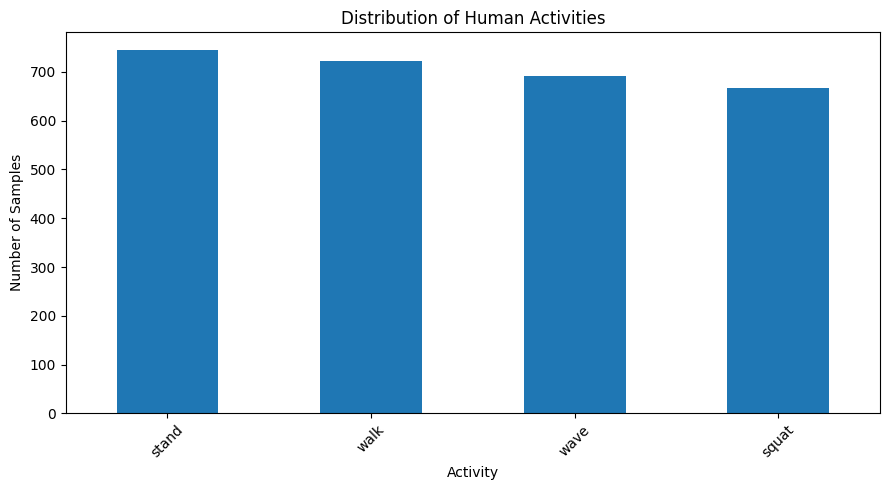

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

class_counts.plot(kind="bar")

plt.title("Distribution of Human Activities")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
# Check missing values in every column

print(df.isnull().sum())

nose_x         0
nose_y         0
neck_x         0
neck_y         0
Rshoulder_x    0
Rshoulder_y    0
Relbow_x       0
Relbow_y       0
Rwrist_x       0
RWrist_y       0
LShoulder_x    0
LShoulder_y    0
LElbow_x       0
LElbow_y       0
LWrist_x       0
LWrist_y       0
RHip_x         0
RHip_y         0
RKnee_x        0
RKnee_y        0
RAnkle_x       0
RAnkle_y       0
LHip_x         0
LHip_y         0
LKnee_x        0
LKnee_y        0
LAnkle_x       0
LAnkle_y       0
REye_x         0
REye_y         0
LEye_x         0
LEye_y         0
REar_x         0
REar_y         0
LEar_x         0
LEar_y         0
class          0
dtype: int64


In [14]:
# Count duplicate rows

duplicate_count = df.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 565


In [15]:
# Select all coordinate columns

X_coordinates = df.drop(columns=["class"])

# Statistical summary

display(X_coordinates.describe())

,nose_x,nose_y,neck_x,neck_y,Rshoulder_x,Rshoulder_y,Relbow_x,Relbow_y,Rwrist_x,RWrist_y,...,LAnkle_x,LAnkle_y,REye_x,REye_y,LEye_x,LEye_y,REar_x,REar_y,LEar_x,LEar_y
count,2826.000000,2826.000000,2826.000000,2826.000000,2826.000000,2826.000000,2826.000000,2826.000000,2826.000000,2826.000000,...,2826.000000,2826.000000,2826.000000,2826.000000,2826.000000,2826.000000,2826.000000,2826.000000,2826.000000,2826.000000
mean,0.466373,0.473390,0.468822,0.535980,0.430729,0.522919,0.409834,0.568567,0.412682,0.590159,...,0.498885,0.899289,0.433238,0.437930,0.433907,0.432555,0.392328,0.419229,0.427799,0.423581
std,0.162359,0.126528,0.160529,0.115908,0.178459,0.150700,0.187246,0.198410,0.194318,0.236794,...,0.164975,0.116257,0.191952,0.167376,0.197945,0.174294,0.210509,0.196563,0.214556,0.191327
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.330000,0.390000,0.340000,0.460000,0.310000,0.460000,0.280000,0.520000,0.290000,0.500000,...,0.380000,0.890000,0.310000,0.390000,0.320000,0.390000,0.270000,0.390000,0.320000,0.390000
50%,0.490000,0.440000,0.490000,0.500000,0.460000,0.500000,0.440000,0.590000,0.440000,0.650000,...,0.510000,0.910000,0.460000,0.440000,0.480000,0.410000,0.440000,0.440000,0.480000,0.410000
75%,0.590000,0.460000,0.590000,0.520000,0.560000,0.540000,0.540000,0.630000,0.560000,0.700000,...,0.610000,0.940000,0.570000,0.460000,0.590000,0.460000,0.560000,0.460000,0.590000,0.460000
max,0.830000,0.720000,0.830000,0.740000,0.820000,0.740000,0.840000,0.850000,0.850000,0.890000,...,0.850000,0.980000,0.820000,0.720000,0.830000,0.700000,0.820000,0.720000,0.840000,0.700000


In [16]:
print("Minimum coordinate:", X_coordinates.min().min())
print("Maximum coordinate:", X_coordinates.max().max())

Minimum coordinate: 0.0
Maximum coordinate: 0.98


In [17]:
# Count duplicate records for each activity

duplicate_rows = df[df.duplicated(keep=False)]

print("Duplicate records by activity:")
print(duplicate_rows["class"].value_counts())

Duplicate records by activity:
class
stand    477
squat    259
wave      37
Name: count, dtype: int64


In [18]:
# Check duplicate coordinate patterns

features = df.drop(columns=["class"])

duplicate_features = features.duplicated(keep=False)

print("Rows with duplicate coordinates:",
      duplicate_features.sum())

print("\nActivity labels among duplicate coordinate rows:")
print(df.loc[duplicate_features, "class"].value_counts())

Rows with duplicate coordinates: 773

Activity labels among duplicate coordinate rows:
class
stand    477
squat    259
wave      37
Name: count, dtype: int64


In [19]:
print("Minimum coordinate value:",
      features.min().min())

print("Maximum coordinate value:",
      features.max().max())

Minimum coordinate value: 0.0
Maximum coordinate value: 0.98


In [20]:
print("Activity distribution:")
print(df["class"].value_counts())

print("\nPercentage distribution:")
print(df["class"].value_counts(normalize=True) * 100)

Activity distribution:
class
stand    744
walk     722
wave     692
squat    668
Name: count, dtype: int64

Percentage distribution:
class
stand    26.326964
walk     25.548478
wave     24.486907
squat    23.637650
Name: proportion, dtype: float64


In [21]:
duplicate_frequency = (
    features.value_counts()
    .value_counts()
    .sort_index()
)

print("Number of coordinate patterns by repetition count:")
print(duplicate_frequency)

Number of coordinate patterns by repetition count:
count
1     2053
2      110
3       32
4       25
5       14
6        6
7        4
8        4
9        2
10       3
11       1
12       1
13       1
16       1
19       1
22       1
24       1
26       1
Name: count, dtype: int64


In [22]:
zero_counts = (features == 0).sum()

print("Zero values in each coordinate:")
display(zero_counts.to_frame(name="Zero Count"))

Zero values in each coordinate:


,Zero Count
nose_x,42
nose_y,42
neck_x,29
neck_y,29
Rshoulder_x,123
Rshoulder_y,123
Relbow_x,183
Relbow_y,183
Rwrist_x,213
RWrist_y,213


In [23]:
# Create a separate copy so the original dataset remains unchanged

data = df.copy()

print("Working dataset created successfully!")
print("Dataset shape:", data.shape)

Working dataset created successfully!
Dataset shape: (2826, 37)


In [24]:
# Remove unnecessary spaces from column names

data.columns = data.columns.str.strip()

print("Updated column names:")
print(data.columns.tolist())

Updated column names:
['nose_x', 'nose_y', 'neck_x', 'neck_y', 'Rshoulder_x', 'Rshoulder_y', 'Relbow_x', 'Relbow_y', 'Rwrist_x', 'RWrist_y', 'LShoulder_x', 'LShoulder_y', 'LElbow_x', 'LElbow_y', 'LWrist_x', 'LWrist_y', 'RHip_x', 'RHip_y', 'RKnee_x', 'RKnee_y', 'RAnkle_x', 'RAnkle_y', 'LHip_x', 'LHip_y', 'LKnee_x', 'LKnee_y', 'LAnkle_x', 'LAnkle_y', 'REye_x', 'REye_y', 'LEye_x', 'LEye_y', 'REar_x', 'REar_y', 'LEar_x', 'LEar_y', 'class']


In [25]:
# Input features: body joint coordinates
X = data.drop(columns=["class"])

# Target: activity name
y = data["class"]

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nActivity labels:")
print(y.unique())

Input feature shape: (2826, 36)
Target shape: (2826,)

Activity labels:
['stand' 'walk' 'squat' 'wave']


In [26]:
# Check whether all coordinate columns contain numerical data

print("Feature data types:")
print(X.dtypes.value_counts())

# Convert coordinate columns to numeric
X = X.apply(pd.to_numeric, errors="coerce")

print("\nMissing values after numeric conversion:")
print(X.isnull().sum().sum())

Feature data types:
float64    36
Name: count, dtype: int64

Missing values after numeric conversion:
0


In [27]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Original activity labels:")
print(label_encoder.classes_)

print("\nEncoded activity labels:")
print(label_encoder.transform(label_encoder.classes_))

Original activity labels:
['squat' 'stand' 'walk' 'wave']

Encoded activity labels:
[0 1 2 3]


In [28]:
print("Final feature shape:", X.shape)
print("Final target shape:", y_encoded.shape)

print("\nFirst five feature records:")
display(X.head())

print("\nFirst five encoded labels:")
print(y_encoded[:5])

Final feature shape: (2826, 36)
Final target shape: (2826,)

First five feature records:


,nose_x,nose_y,neck_x,neck_y,Rshoulder_x,Rshoulder_y,Relbow_x,Relbow_y,Rwrist_x,RWrist_y,...,LAnkle_x,LAnkle_y,REye_x,REye_y,LEye_x,LEye_y,REar_x,REar_y,LEar_x,LEar_y
0,0.55,0.46,0.54,0.52,0.51,0.52,0.52,0.57,0.54,0.50,...,0.57,0.91,0.54,0.46,0.00,0.00,0.52,0.46,0.55,0.46
1,0.54,0.46,0.54,0.52,0.51,0.52,0.49,0.61,0.50,0.65,...,0.57,0.91,0.54,0.46,0.55,0.46,0.52,0.46,0.56,0.46
2,0.54,0.46,0.54,0.52,0.51,0.52,0.49,0.59,0.50,0.65,...,0.57,0.91,0.54,0.46,0.55,0.46,0.52,0.46,0.56,0.46
3,0.54,0.46,0.54,0.52,0.51,0.52,0.49,0.59,0.50,0.65,...,0.57,0.91,0.54,0.44,0.55,0.44,0.52,0.46,0.55,0.46
4,0.54,0.46,0.54,0.52,0.51,0.52,0.50,0.59,0.51,0.65,...,0.57,0.91,0.54,0.44,0.55,0.44,0.52,0.46,0.55,0.46



First five encoded labels:
[1 1 1 1 1]


In [29]:
# Check dataset size before removing duplicates

print("Before removing duplicates:", data.shape)

# Remove exact duplicate rows
data = data.drop_duplicates()

# Reset row numbering
data = data.reset_index(drop=True)

print("After removing duplicates:", data.shape)

print("Remaining duplicate records:", data.duplicated().sum())

Before removing duplicates: (2826, 37)
After removing duplicates: (2261, 37)
Remaining duplicate records: 0


In [30]:
X = data.drop(columns=["class"])
y = data["class"]

print("Features:", X.shape)
print("Labels:", y.shape)

print("\nActivity distribution:")
print(y.value_counts())

Features: (2261, 36)
Labels: (2261,)

Activity distribution:
class
walk     722
wave     673
squat    499
stand    367
Name: count, dtype: int64


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (1808, 36)
Testing features: (453, 36)
Training labels: (1808,)
Testing labels: (453,)


In [32]:
print("Training activity distribution:")
print(y_train.value_counts())

print("\nTesting activity distribution:")
print(y_test.value_counts())

Training activity distribution:
class
walk     577
wave     538
squat    399
stand    294
Name: count, dtype: int64

Testing activity distribution:
class
walk     145
wave     135
squat    100
stand     73
Name: count, dtype: int64


In [33]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Learn scaling parameters from training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to testing data
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (1808, 36)
Scaled testing shape: (453, 36)


In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [35]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
# Model 1: Decision Tree
dt_model = DecisionTreeClassifier(
    random_state=42
)

# Model 2: Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Model 3: Support Vector Machine
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    random_state=42
)

# Model 4: K-Nearest Neighbors
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

print("All four ML models initialized successfully!")

All four ML models initialized successfully!


In [37]:
print("Training Decision Tree...")
dt_model.fit(X_train, y_train)

print("Training Random Forest...")
rf_model.fit(X_train, y_train)

print("Training SVM...")
svm_model.fit(X_train_scaled, y_train)

print("Training KNN...")
knn_model.fit(X_train_scaled, y_train)

print("\nAll models trained successfully!")

Training Decision Tree...
Training Random Forest...
Training SVM...
Training KNN...

All models trained successfully!


In [38]:
dt_predictions = dt_model.predict(X_test)

rf_predictions = rf_model.predict(X_test)

svm_predictions = svm_model.predict(X_test_scaled)

knn_predictions = knn_model.predict(X_test_scaled)

print("Predictions generated successfully!")

Predictions generated successfully!


In [40]:
models_predictions = {
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions,
    "SVM": svm_predictions,
    "KNN": knn_predictions
}

results = []

for model_name, predictions in models_predictions.items():

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test, predictions,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test, predictions,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy (%)": round(accuracy * 100, 2),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1 Score (%)": round(f1 * 100, 2)
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="Accuracy (%)",
        ascending=False
    )
)

,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
1,Random Forest,100.00,100.00,100.00,100.00
2,SVM,99.78,99.78,99.78,99.78
0,Decision Tree,99.34,99.34,99.34,99.34
3,KNN,99.34,99.35,99.34,99.34


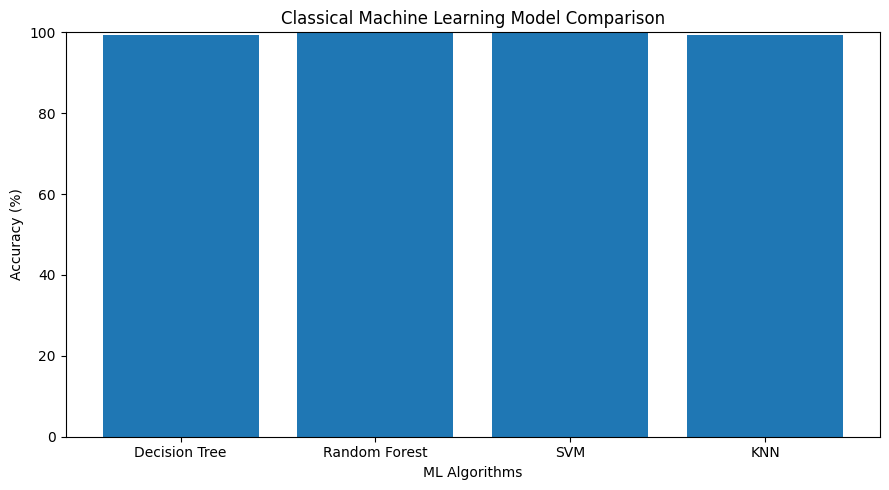

In [41]:
plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy (%)"]
)

plt.title("Classical Machine Learning Model Comparison")
plt.xlabel("ML Algorithms")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [42]:
print("Random Forest Classification Report")

print(
    classification_report(
        y_test,
        rf_predictions,
        labels=["squat", "stand", "walk", "wave"],
        zero_division=0
    )
)

Random Forest Classification Report
              precision    recall  f1-score   support

       squat       1.00      1.00      1.00       100
       stand       1.00      1.00      1.00        73
        walk       1.00      1.00      1.00       145
        wave       1.00      1.00      1.00       135

    accuracy                           1.00       453
   macro avg       1.00      1.00      1.00       453
weighted avg       1.00      1.00      1.00       453



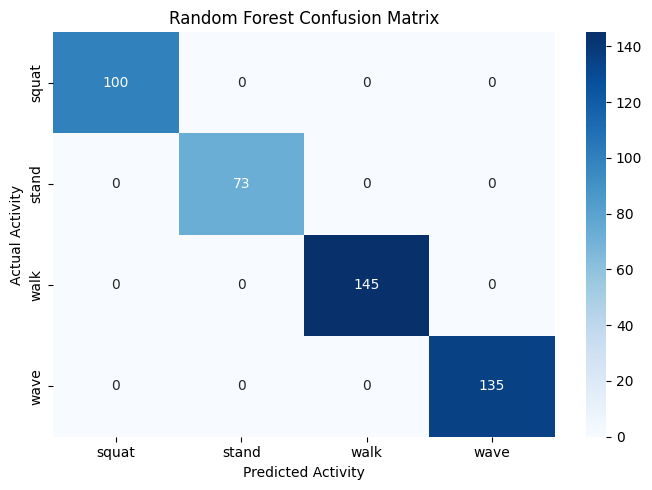

In [43]:
cm = confusion_matrix(
    y_test,
    rf_predictions,
    labels=["squat", "stand", "walk", "wave"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["squat", "stand", "walk", "wave"],
    yticklabels=["squat", "stand", "walk", "wave"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")

plt.tight_layout()
plt.show()

In [44]:
print("MODEL PERFORMANCE COMPARISON")
display(results_df.sort_values(
    by="Accuracy (%)",
    ascending=False
))

print("\nExact Random Forest Accuracy:")
print(accuracy_score(y_test, rf_predictions))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
1,Random Forest,100.00,100.00,100.00,100.00
2,SVM,99.78,99.78,99.78,99.78
0,Decision Tree,99.34,99.34,99.34,99.34
3,KNN,99.34,99.35,99.34,99.34



Exact Random Forest Accuracy:
1.0


In [45]:
# Check whether identical coordinate rows
# appear in both training and testing datasets

train_poses = set(
    map(tuple, X_train.to_numpy())
)

test_poses = set(
    map(tuple, X_test.to_numpy())
)

overlapping_poses = train_poses.intersection(test_poses)

print(
    "Identical coordinate patterns in both sets:",
    len(overlapping_poses)
)

Identical coordinate patterns in both sets: 0


In [46]:
# Find coordinate patterns associated with multiple classes

pose_label_counts = (
    data.groupby(list(X.columns))["class"]
    .nunique()
)

conflicting_poses = (pose_label_counts > 1).sum()

print(
    "Coordinate patterns having different activity labels:",
    conflicting_poses
)

Coordinate patterns having different activity labels: 0


In [47]:
print("Random Forest Confusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

Random Forest Confusion Matrix:
[[100   0   0   0]
 [  0  73   0   0]
 [  0   0 145   0]
 [  0   0   0 135]]


In [48]:
import pandas as pd
import numpy as np

def predict_activity():

    print("HUMAN ACTIVITY RECOGNITION")
    print("-" * 40)

    input_values = []

    # Ask the user to enter each joint coordinate
    for feature in X.columns:

        value = float(input(f"Enter {feature}: "))
        input_values.append(value)

    # Convert input into DataFrame
    input_data = pd.DataFrame(
        [input_values],
        columns=X.columns
    )

    # Predict activity
    prediction = rf_model.predict(input_data)

    print("\n" + "=" * 40)
    print("PREDICTED HUMAN ACTIVITY:", prediction[0])
    print("=" * 40)

In [50]:
predict_activity()

HUMAN ACTIVITY RECOGNITION
----------------------------------------
Enter nose_x: 0.50
Enter nose_y: 0.12
Enter neck_x: 0.50
Enter neck_y: 0.25
Enter Rshoulder_x: 0.40
Enter Rshoulder_y: 0.28
Enter Relbow_x: 0.36
Enter Relbow_y: 0.42
Enter Rwrist_x: 0.35
Enter RWrist_y: 0.55
Enter LShoulder_x: 0.60
Enter LShoulder_y: 0.28
Enter LElbow_x: 0.64
Enter LElbow_y: 0.42
Enter LWrist_x: 0.65
Enter LWrist_y: 0.55
Enter RHip_x: 0.44
Enter RHip_y: 0.52
Enter RKnee_x: 0.44
Enter RKnee_y: 0.73
Enter RAnkle_x: 0.44
Enter RAnkle_y: 0.73
Enter LHip_x: 0.56
Enter LHip_y: 0.52
Enter LKnee_x: 0.56
Enter LKnee_y: 0.73
Enter LAnkle_x: 0.56
Enter LAnkle_y: 0.94
Enter REye_x: 0
Enter REye_y: 0.13
Enter LEye_x: 0.53
Enter LEye_y: 0.13
Enter REar_x: 0.43
Enter REar_y: 0.15
Enter LEar_x: 0.57
Enter LEar_y: 0.15

PREDICTED HUMAN ACTIVITY: walk


data leakage

In [51]:
# Check identical coordinate patterns
train_poses = set(map(tuple, X_train.to_numpy()))
test_poses = set(map(tuple, X_test.to_numpy()))

overlapping_poses = train_poses.intersection(test_poses)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Identical poses in both sets:", len(overlapping_poses))

# Check whether the same pose has different activity labels
pose_label_counts = data.groupby(
    list(X.columns)
)["class"].nunique()

conflicting_poses = (pose_label_counts > 1).sum()

print("Poses with conflicting activity labels:", conflicting_poses)

Training samples: 1808
Testing samples: 453
Identical poses in both sets: 0
Poses with conflicting activity labels: 0


In [52]:
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Define all four models
models = {
    "Decision Tree": Pipeline([
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", C=1.0))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ])
}

# Five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():

    # Train using training data
    model.fit(X_train, y_train)

    # Predict on unseen test data
    predictions = model.predict(X_test)

    # Calculate test metrics
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, predictions, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, predictions, average="weighted", zero_division=0
    )

    # Cross-validation on training data
    cv_results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=["accuracy", "f1_weighted"]
    )

    results.append({
        "Model": name,
        "Test Accuracy": accuracy * 100,
        "Precision": precision * 100,
        "Recall": recall * 100,
        "F1 Score": f1 * 100,
        "CV Accuracy": cv_results["test_accuracy"].mean() * 100,
        "CV F1 Score": cv_results["test_f1_weighted"].mean() * 100
    })

# Display comparison
results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(2))

MODEL PERFORMANCE COMPARISON


,Model,Test Accuracy,Precision,Recall,F1 Score,CV Accuracy,CV F1 Score
0,Decision Tree,99.34,99.34,99.34,99.34,99.83,99.83
1,Random Forest,100.00,100.00,100.00,100.00,99.83,99.83
2,SVM,99.78,99.78,99.78,99.78,99.50,99.50
3,KNN,99.34,99.35,99.34,99.34,99.45,99.45


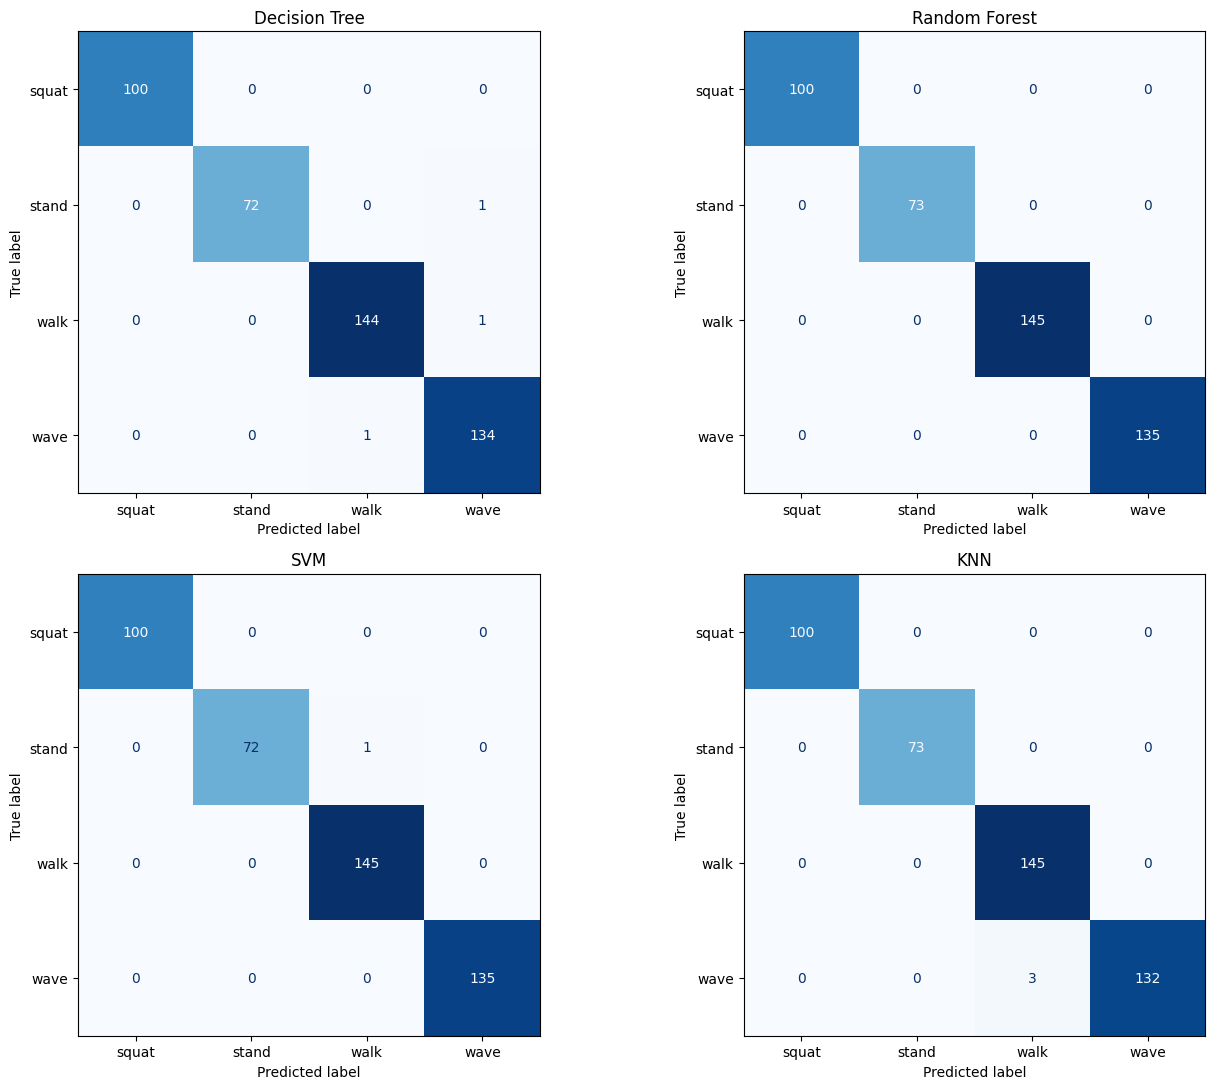

In [53]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Create confusion matrices for all models
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for (name, model), ax in zip(models.items(), axes.flatten()):

    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=model.classes_
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=model.classes_
    )

    display_matrix.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [54]:
from sklearn.metrics import classification_report

for name, model in models.items():

    predictions = model.predict(X_test)

    print("\n================================")
    print("MODEL:", name)
    print("================================")

    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))


MODEL: Decision Tree
              precision    recall  f1-score   support

       squat       1.00      1.00      1.00       100
       stand       1.00      0.99      0.99        73
        walk       0.99      0.99      0.99       145
        wave       0.99      0.99      0.99       135

    accuracy                           0.99       453
   macro avg       0.99      0.99      0.99       453
weighted avg       0.99      0.99      0.99       453


MODEL: Random Forest
              precision    recall  f1-score   support

       squat       1.00      1.00      1.00       100
       stand       1.00      1.00      1.00        73
        walk       1.00      1.00      1.00       145
        wave       1.00      1.00      1.00       135

    accuracy                           1.00       453
   macro avg       1.00      1.00      1.00       453
weighted avg       1.00      1.00      1.00       453


MODEL: SVM
              precision    recall  f1-score   support

       squat       

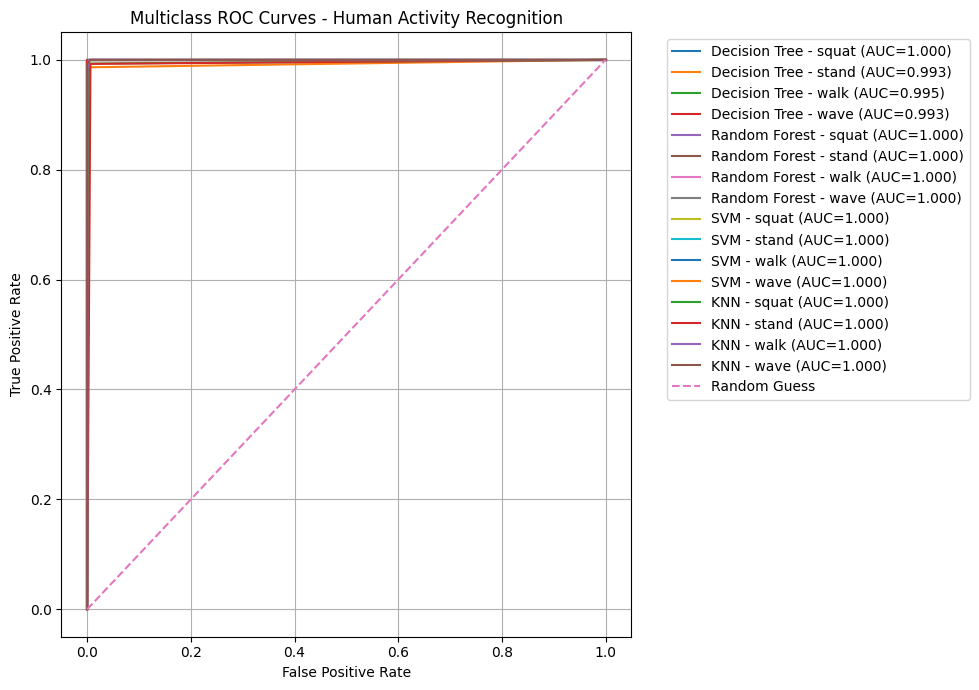

In [56]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.svm import SVC

# 1. Update SVC configuration in pipeline to support probability estimates
models["SVM"].set_params(model__probability=True)

# 2. Re-fit models to ensure they are ready to yield predict_proba
for name, model in models.items():
    model.fit(X_train, y_train)

# 3. Convert actual labels into binary format
classes = models["Random Forest"].classes_
y_test_binary = label_binarize(
    y_test,
    classes=classes
)

# Plot ROC curves
plt.figure(figsize=(10, 7))

for name, model in models.items():
    # Get prediction probabilities
    probabilities = model.predict_proba(X_test)

    # Calculate macro-average AUC
    macro_auc = roc_auc_score(
        y_test_binary,
        probabilities,
        average="macro",
        multi_class="ovr"
    )

    # Plot one ROC curve per activity
    for i, activity in enumerate(classes):
        fpr, tpr, thresholds = roc_curve(
            y_test_binary[:, i],
            probabilities[:, i]
        )
        roc_auc = auc(fpr, tpr)
        plt.plot(
            fpr,
            tpr,
            label=f"{name} - {activity} (AUC={roc_auc:.3f})"
        )

# Random guessing reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guess"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves - Human Activity Recognition")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid()
plt.tight_layout()
plt.show()

In [57]:
auc_results = []

for name, model in models.items():

    probabilities = model.predict_proba(X_test)

    macro_auc = roc_auc_score(
        y_test_binary,
        probabilities,
        average="macro",
        multi_class="ovr"
    )

    auc_results.append({
        "Model": name,
        "Macro Average AUC": round(macro_auc, 4)
    })

auc_df = pd.DataFrame(auc_results)

display(auc_df)

,Model,Macro Average AUC
0,Decision Tree,0.9953
1,Random Forest,1.0000
2,SVM,1.0000
3,KNN,1.0000


Hyperparameter tuning

In [58]:
import pandas as pd

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [59]:
tuning_models = {
    "Decision Tree": {
        "pipeline": Pipeline([
            ("model", DecisionTreeClassifier(random_state=42))
        ]),
        "params": {
            "model__criterion": ["gini", "entropy"],
            "model__max_depth": [None, 5, 10, 20],
            "model__min_samples_split": [2, 5, 10]
        }
    },

    "Random Forest": {
        "pipeline": Pipeline([
            ("model", RandomForestClassifier(random_state=42))
        ]),
        "params": {
            "model__n_estimators": [100, 200, 300],
            "model__max_depth": [None, 10, 20],
            "model__min_samples_split": [2, 5]
        }
    },

    "SVM": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC(kernel="rbf"))
        ]),
        "params": {
            "model__C": [0.1, 1, 10],
            "model__gamma": ["scale", "auto"]
        }
    },

    "KNN": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier())
        ]),
        "params": {
            "model__n_neighbors": [3, 5, 7, 9],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }
    }
}

In [60]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best_models = {}
tuning_results = []

for name, config in tuning_models.items():

    print("\nTuning:", name)

    grid = GridSearchCV(
        estimator=config["pipeline"],
        param_grid=config["params"],
        scoring="f1_weighted",
        cv=cv,
        n_jobs=-1,
        verbose=1
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV F1 Score": grid.best_score_ * 100,
        "Best Parameters": grid.best_params_
    })

    print("Best parameters:", grid.best_params_)
    print("Best CV F1 Score:", round(grid.best_score_ * 100, 2), "%")

tuning_df = pd.DataFrame(tuning_results)

print("\nHYPERPARAMETER TUNING RESULTS")
display(tuning_df)


Tuning: Decision Tree
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters: {'model__criterion': 'gini', 'model__max_depth': None, 'model__min_samples_split': 2}
Best CV F1 Score: 99.83 %

Tuning: Random Forest
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV F1 Score: 99.89 %

Tuning: SVM
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters: {'model__C': 10, 'model__gamma': 'scale'}
Best CV F1 Score: 99.83 %

Tuning: KNN
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters: {'model__n_neighbors': 3, 'model__p': 1, 'model__weights': 'uniform'}
Best CV F1 Score: 100.0 %

HYPERPARAMETER TUNING RESULTS


,Model,Best CV F1 Score,Best Parameters
0,Decision Tree,99.834122,"{'model__criterion': 'gini', 'model__max_depth..."
1,Random Forest,99.889348,"{'model__max_depth': None, 'model__min_samples..."
2,SVM,99.834253,"{'model__C': 10, 'model__gamma': 'scale'}"
3,KNN,100.000000,"{'model__n_neighbors': 3, 'model__p': 1, 'mode..."


In [61]:
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

final_results = []

for name, model in best_models.items():

    predictions = model.predict(X_test)

    final_results.append({
        "Model": name,
        "Test Accuracy": accuracy_score(
            y_test, predictions
        ) * 100,

        "Precision": precision_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        ) * 100,

        "Recall": recall_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        ) * 100,

        "F1 Score": f1_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        ) * 100
    })

final_results_df = pd.DataFrame(final_results)

print("TUNED MODEL PERFORMANCE")
display(final_results_df.round(2))

TUNED MODEL PERFORMANCE


,Model,Test Accuracy,Precision,Recall,F1 Score
0,Decision Tree,99.34,99.34,99.34,99.34
1,Random Forest,100.00,100.00,100.00,100.00
2,SVM,99.78,99.78,99.78,99.78
3,KNN,100.00,100.00,100.00,100.00


In [62]:
# Select the best model using cross-validation F1-score
best_model_name = tuning_df.loc[
    tuning_df["Best CV F1 Score"].idxmax(),
    "Model"
]

final_model = best_models[best_model_name]

print("Selected Model:", best_model_name)
print("Best CV F1 Score:",
      tuning_df["Best CV F1 Score"].max())

Selected Model: KNN
Best CV F1 Score: 100.0


In [63]:
from sklearn.metrics import classification_report

final_predictions = final_model.predict(X_test)

print("FINAL MODEL:", best_model_name)

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_predictions,
    zero_division=0
))

FINAL MODEL: KNN

Classification Report:
              precision    recall  f1-score   support

       squat       1.00      1.00      1.00       100
       stand       1.00      1.00      1.00        73
        walk       1.00      1.00      1.00       145
        wave       1.00      1.00      1.00       135

    accuracy                           1.00       453
   macro avg       1.00      1.00      1.00       453
weighted avg       1.00      1.00      1.00       453



In [64]:
import joblib

# Prepare model package
model_package = {
    "model": final_model,
    "model_name": best_model_name,
    "feature_columns": list(X.columns),
    "activity_classes": list(final_model.classes_)
}

# Save model package
joblib.dump(model_package, "human_activity_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [65]:
from google.colab import files

files.download("human_activity_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [69]:
from sklearn.preprocessing import LabelEncoder
from sklearn.base import clone
import joblib

# Encode activity labels
final_label_encoder = LabelEncoder()

y_train_encoded = final_label_encoder.fit_transform(y_train)

# Create a fresh copy of the selected model
fixed_model = clone(final_model)

# Train using numerical labels
fixed_model.fit(X_train, y_train_encoded)

print("Activity encoding:")
for number, activity in enumerate(final_label_encoder.classes_):
    print(number, "=", activity)

Activity encoding:
0 = squat
1 = stand
2 = walk
3 = wave


In [70]:
# Select one unseen test sample
sample = X_test.iloc[[0]]

# Predict numerical activity
prediction_encoded = fixed_model.predict(sample)[0]

# Convert numerical prediction to activity name
prediction = final_label_encoder.inverse_transform(
    [int(prediction_encoded)]
)[0]

print("Predicted Activity:", prediction)
print("Actual Activity:", y_test.iloc[0])

Predicted Activity: wave
Actual Activity: wave


In [71]:
model_package = {
    "model": fixed_model,
    "model_name": best_model_name,
    "label_encoder": final_label_encoder,
    "feature_columns": list(X.columns),
    "activity_classes": list(final_label_encoder.classes_)
}

joblib.dump(
    model_package,
    "human_activity_model.pkl"
)

print("Corrected model saved successfully!")

Corrected model saved successfully!


In [72]:
loaded_package = joblib.load("human_activity_model.pkl")

loaded_model = loaded_package["model"]
loaded_encoder = loaded_package["label_encoder"]

sample = X_test.iloc[[0]]

predicted_number = loaded_model.predict(sample)[0]

predicted_activity = loaded_encoder.inverse_transform(
    [int(predicted_number)]
)[0]

print("Predicted Activity:", predicted_activity)
print("Actual Activity:", y_test.iloc[0])

Predicted Activity: wave
Actual Activity: wave
